# ViT MONAI XAI

## Load Dataset

In [17]:
from pathlib import Path
from collections import Counter
from monai.data import Dataset
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, Resized, ScaleIntensityd, EnsureTyped,
)

DATA_DIR = Path(r"..\..\data\brain-tumor-mri-classification\merged_dataset_v3\images")
assert DATA_DIR.exists(), f"Not found: {DATA_DIR.resolve()}"   # relative path depends on the notebook's working directory

class_names = ["glioma", "meningioma", "no_tumor", "pituitary"]
class_to_idx = {name: idx for idx, name in enumerate(class_names)}

def get_image_files(split):
    data = []
    for class_name in class_names:
        class_dir = DATA_DIR / split / class_name
        for image_path in sorted(class_dir.iterdir()):          # sorted = deterministic order
            if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                data.append({"image": str(image_path), "label": class_to_idx[class_name]})
    return data

transforms = Compose([
    LoadImaged(keys=["image"]),
    EnsureChannelFirstd(keys=["image"]),
    Resized(keys=["image"], spatial_size=(224, 224)),
    ScaleIntensityd(keys=["image"]),
    EnsureTyped(keys=["image"]),
])

test_files = get_image_files("test")

test_dataset = Dataset(data=test_files, transform=transforms)

print("test:", len(test_files))
print("test per class:", Counter(class_names[d["label"]] for d in test_files))
print("sample:", tuple(test_dataset[0]["image"].shape))

test: 246
test per class: Counter({'glioma': 81, 'pituitary': 61, 'meningioma': 55, 'no_tumor': 49})
sample: (3, 224, 224)


## Load Model

In [18]:
MODEL_PATH = r"../../models/monai_vit.pt"

In [19]:
import torch, torch.nn as nn
from monai.networks.nets import ViT

class ViTForXAI(nn.Module):
    # attribute name `vit_model` must match the checkpoint's key prefix
    def __init__(self, num_heads=12):
        super().__init__()
        self.vit_model = ViT(
            in_channels=3, img_size=224, patch_size=16,
            hidden_size=768, mlp_dim=3072, num_layers=12, num_heads=num_heads,
            proj_type="conv", pos_embed_type="learnable",
            classification=True, num_classes=4, dropout_rate=0.0,
            spatial_dims=2, qkv_bias=False, save_attn=True,
        )
    def forward(self, x):
        logits, _ = self.vit_model(x)   # MONAI ViT returns (output, hidden_states)
        return logits

device = torch.device("cuda:0")
sd = torch.load(MODEL_PATH, map_location="cpu")
model = ViTForXAI()
print(model.load_state_dict(sd, strict=True))   # expect: <All keys matched successfully>
model.to(device).eval()

with torch.no_grad():
    out = model(torch.zeros(1, 3, 224, 224, device=device))
print(tuple(out.shape))                                      # expect (1, 4)
print(tuple(model.vit_model.blocks[0].attn.att_mat.shape))   # expect (1, 12, 197, 197)

<All keys matched successfully>
(1, 4)
(1, 12, 197, 197)


## Apply Attention Rollout

In [20]:
import numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt

class_names = ["glioma", "meningioma", "no_tumor", "pituitary"]

@torch.no_grad()
def attention_rollout(model, x):
    """x: [1, 3, 224, 224]. Returns (patch map [14, 14] scaled to 0-1, logits)."""
    logits = model(x)  # forward pass fills blk.attn.att_mat in every block
    layers = [blk.attn.att_mat[0] for blk in model.vit_model.blocks]  # each [heads, N, N]
    N = layers[0].shape[-1]
    eye = torch.eye(N, device=x.device)
    rollout = eye.clone()
    for A in layers:
        A = A.mean(dim=0)              # average over heads
        A = 0.5 * A + 0.5 * eye        # account for the residual connection
        A = A / A.sum(dim=-1, keepdim=True)
        rollout = A @ rollout          # accumulate from first to last layer
    assert torch.allclose(rollout.sum(-1), torch.ones(N, device=x.device), atol=1e-4)
    cls_to_patches = rollout[0, 1:]    # [CLS] row, patch columns only -> 196 values
    side = int(cls_to_patches.numel() ** 0.5)
    m = cls_to_patches.reshape(side, side)
    m = (m - m.min()) / (m.max() - m.min() + 1e-8)
    return m, logits

In [21]:
def show_rollout(model, sample, device):
    x = sample["image"].unsqueeze(0).to(device)
    m, logits = attention_rollout(model, x)
    pred = logits.argmax(1).item()
    heat = F.interpolate(m[None, None], size=x.shape[-2:], mode="bilinear",
                         align_corners=False)[0, 0].cpu().numpy()
    img = x[0].permute(1, 2, 0).cpu().numpy().clip(0, 1)
    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    ax[0].imshow(img);                          ax[0].set_title(f"true: {class_names[int(sample['label'])]}")
    ax[1].imshow(heat, cmap="jet");             ax[1].set_title("rollout map")
    ax[2].imshow(img); ax[2].imshow(heat, cmap="jet", alpha=0.45)
    ax[2].set_title(f"overlay | pred: {class_names[pred]}")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

glioma | rf_test_glioma_725.jpg


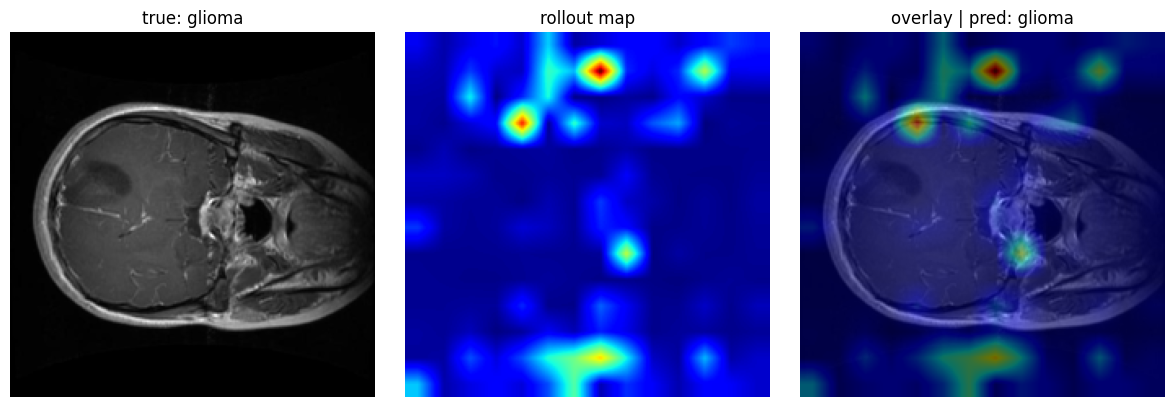

meningioma | rf_test_meningioma_491.jpg


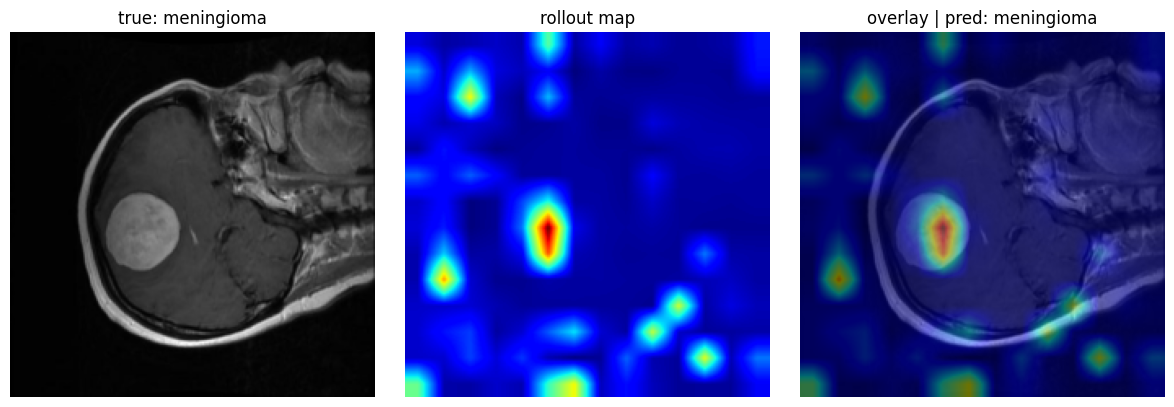

no_tumor | rf_test_no_tumor_435.jpg


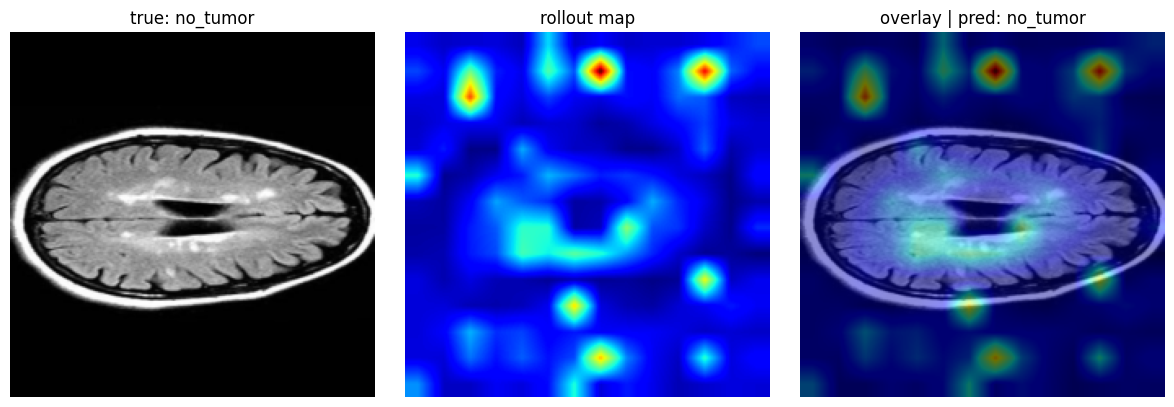

pituitary | rf_test_pituitary_550.jpg


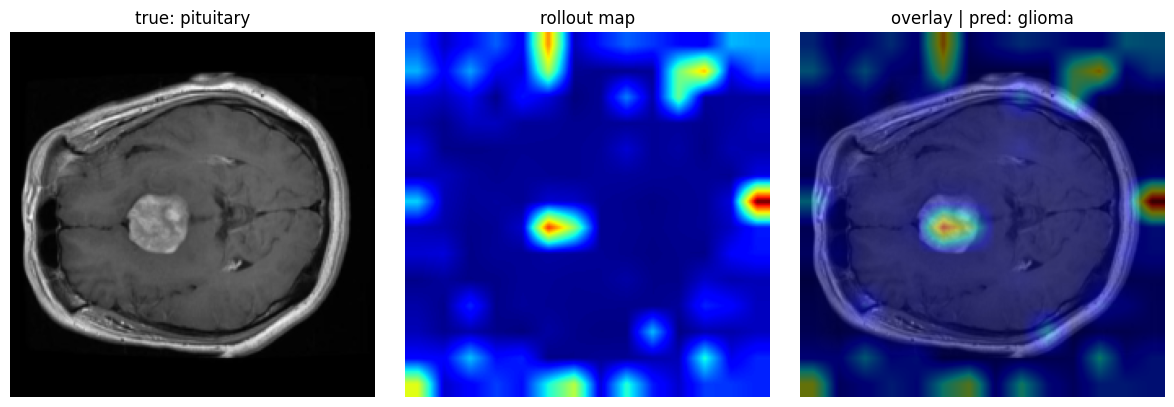

In [23]:
# First test file per class by sorted path (deterministic, no hand-picking)
by_class = {}
for idx, d in sorted(enumerate(test_files), key=lambda t: t[1]["image"]):
    by_class.setdefault(d["label"], idx)

for c in sorted(by_class):
    i = by_class[c]
    print(f"{class_names[c]} | {Path(test_files[i]['image']).name}")
    show_rollout(model, test_dataset[i], device)